# 05 — Exploratory Data Analysis
The final notebook interprets business metrics, groupby tables, a pivot table, and charts. Sales value is shown in GBP; it is not profit because cost data is unavailable.

## Learning objectives
- Understand the difference between invoice-level and line-level metrics
- Create monthly, product, and country summaries
- Read a pivot table and Seaborn visualizations

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from retail_analysis.data_loader import load_retail_data
from retail_analysis.cleaning import clean_transactions, split_transaction_sets
from retail_analysis.features import add_transaction_features, create_customer_features
from retail_analysis.analysis import key_metrics, monthly_sales, top_products, top_countries, weekday_hour_sales, cancellation_summary

cleaned, _ = clean_transactions(load_retail_data())
sales, cancellations, _ = split_transaction_sets(cleaned)
sales = add_transaction_features(sales)
key_metrics(sales)

,Metric,Value
0,TotalEligibleSalesGBP,1.064211e+07
1,UniqueOrders,1.996000e+04
2,IdentifiedCustomers,4.338000e+03
3,AverageOrderValueGBP,5.331719e+02


Average Order Value is the mean of invoice totals. Numeric correlations involving InvoiceNo or CustomerID are not meaningful because these fields are identifiers.

In [2]:
monthly = monthly_sales(sales)
monthly

,YearMonth,LineValue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


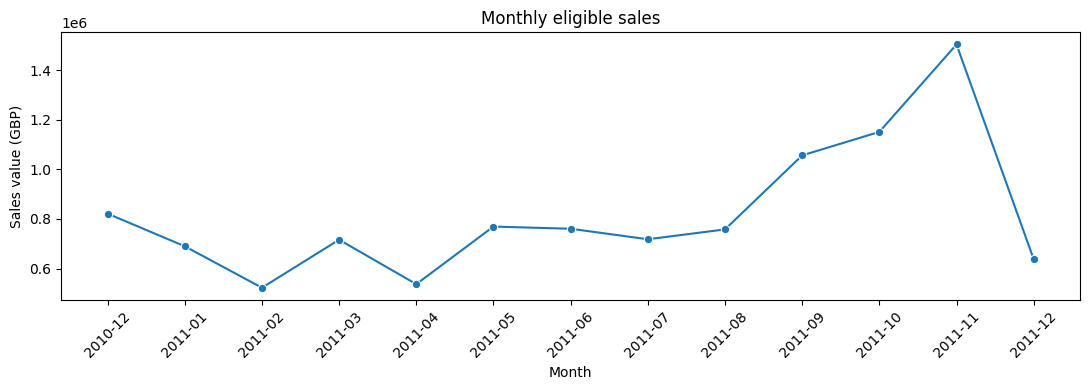

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=monthly, x='YearMonth', y='LineValue', marker='o', ax=ax)
ax.set(title='Monthly eligible sales', xlabel='Month', ylabel='Sales value (GBP)')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

The first and last reporting periods may be incomplete, so monthly differences should not automatically be described as business growth. A missing month is not filled with zero sales.

In [4]:
top_products(sales, by='LineValue')

,StockCode,Quantity,LineValue,Description
0,DOT,706,206248.77,DOTCOM POSTAGE
1,22423,13851,174156.54,REGENCY CAKESTAND 3 TIER
2,23843,80995,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
3,85123A,37641,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
4,47566,18283,99445.23,PARTY BUNTING
5,85099B,48371,94159.81,JUMBO BAG RED RETROSPOT
6,23166,78033,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
7,POST,3150,78101.88,POSTAGE
8,M,6984,77750.27,Manual
9,23084,30739,66870.03,RABBIT NIGHT LIGHT


In [5]:
top_countries(sales)

,Country,LineValue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


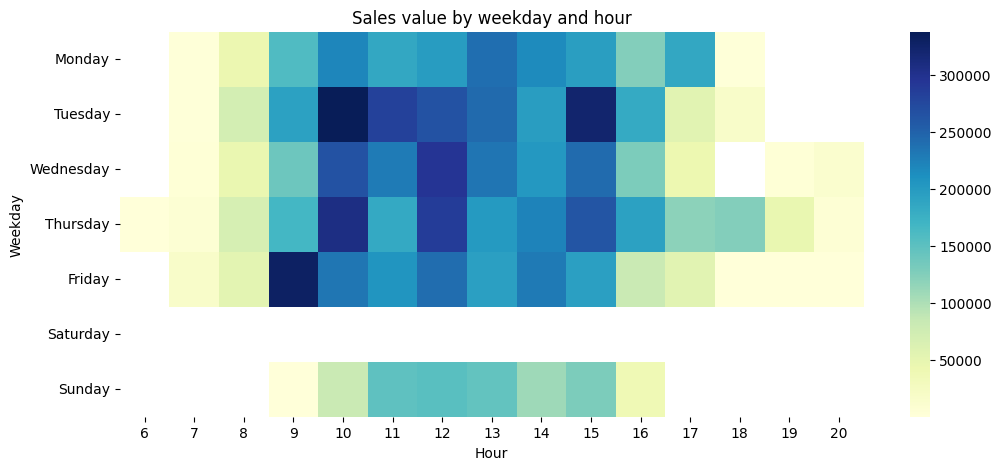

In [6]:
# pivot_table sums sales into weekday rows and hour columns
heat = weekday_hour_sales(sales)
plt.figure(figsize=(12, 5))
sns.heatmap(heat, cmap='YlGnBu')
plt.title('Sales value by weekday and hour'); plt.xlabel('Hour'); plt.ylabel('Weekday')
plt.show()

In [7]:
cancellation_summary(cancellations)

,Metric,Value
0,CancellationLines,9251.00
1,CancellationInvoices,3836.00
2,SignedLineValueGBP,-893979.73


## Interpretation and practice questions
StockCode is the product grouping key, while Description is only a label. Cancellations and signed line values are reported separately from positive sales, so eligible sales are not described as `net revenue`.

1. Do the top products differ when ranked by Quantity and sales value?
2. Which cell has the highest value in the weekday/hour heatmap?
3. Remove the UK, recalculate the top countries, and revise the interpretation.